In [ ]:
!pip install mediapipe

  Using cached mediapipe-1.1.0-py3-none-win_amd64.whl.metadata (10 kB)
  Using cached sounddevice-0.5.6-py3-none-win_amd64.whl.metadata (1.4 kB)
  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached mediapipe-1.1.0-py3-none-win_amd64.whl (22.4 MB)
Using cached sounddevice-0.5.6-py3-none-win_amd64.whl (1.0 MB)
Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl (53.8 MB)

   ---------------------------------------- 0/3 [opencv-contrib-python]
   ---------------------------------------- 0/3 [opencv-contrib-python]
   ---------------------------------------- 0/3 [opencv-contrib-python]
   ---------------------------------------- 0/3 [opencv-contrib-python]
   ------------- -------------------------- 1/3 [sounddevice]
   -------------------------- ------------- 2/3 [mediapipe]
   -------------------------- ------------- 2/3 [mediapipe]
   -------------------------- ------------- 2/3 [mediapipe]
   -------------------------- ----

In [2]:
# %pip install mediapipe
# # opencv-python numpy matplotlib

import os
import sys
import time
import threading
import urllib.request

import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

print("All libraries loaded!")

All libraries loaded!


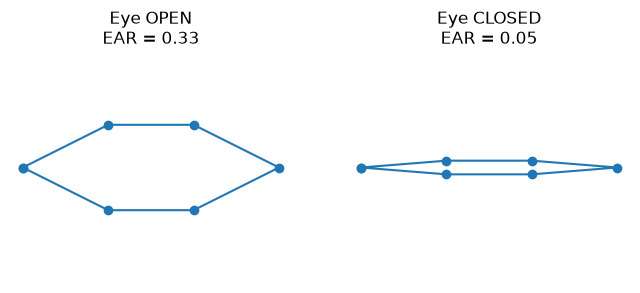

In [3]:
def eye_aspect_ratio(p):
    # p holds 6 points: p[0] = left corner, p[3] = right corner,
    # p[1], p[2] = upper lid, p[5], p[4] = lower lid
    height_1 = np.linalg.norm(p[1] - p[5])
    height_2 = np.linalg.norm(p[2] - p[4])
    width = np.linalg.norm(p[0] - p[3])
    return (height_1 + height_2) / (2.0 * width)


def make_demo_eye(openness):
    return np.array([[0, 0], [1, openness], [2, openness],
                     [3, 0], [2, -openness], [1, -openness]], dtype=float)


plt.figure(figsize=(8, 3))
for i, (name, openness) in enumerate([("Eye OPEN", 0.5), ("Eye CLOSED", 0.08)]):
    eye = make_demo_eye(openness)
    plt.subplot(1, 2, i + 1)
    outline = np.vstack([eye, eye[0]])
    plt.plot(outline[:, 0], outline[:, 1], "-o")
    plt.title(f"{name}\nEAR = {eye_aspect_ratio(eye):.2f}")
    plt.ylim(-1, 1); plt.axis("equal"); plt.axis("off")
plt.show()

In [4]:
DROWSY_SECONDS = 1.5          # eyes closed this long = DROWSY  (blinks are much shorter)
MIN_BLINK_SECONDS = 0.05      # closures shorter than this are noise, ignore them
CALIBRATION_SECONDS = 3       # time to learn YOUR open-eye EAR at the start
THRESHOLD_FRACTION = 0.75     # "closed" = EAR below 75% of your normal open-eye EAR
DEFAULT_EAR_THRESHOLD = 0.21  # used only if calibration fails
CAMERA_NUMBER = 0             # 0 = default webcam, try 1 if it does not open

In [5]:
MODEL_FILE = "face_landmarker.task"
MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
             "face_landmarker/float16/1/face_landmarker.task")

if not os.path.exists(MODEL_FILE):
    print("Downloading the face model (one time only)...")
    urllib.request.urlretrieve(MODEL_URL, MODEL_FILE)

print("Face model ready:", MODEL_FILE)

Face model ready: face_landmarker.task


In [6]:
options = vision.FaceLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path=MODEL_FILE),
    num_faces=1)                      # we only watch one driver
detector = vision.FaceLandmarker.create_from_options(options)

# Numbers of the 6 points around each eye (in the order used by our EAR formula)
RIGHT_EYE = [33, 160, 158, 133, 153, 144]
LEFT_EYE = [362, 385, 387, 263, 373, 380]
print("Detector ready!")

Detector ready!


In [7]:
state = {"closed_since": None, "blinks": 0, "alerts": 0, "alarm_on": False}


def check_eyes(ear, now, threshold):
    """Update the system and return how many seconds the eyes have been closed."""
    closed_time = 0.0

    if ear < threshold:                              # eyes look CLOSED
        if state["closed_since"] is None:
            state["closed_since"] = now              # start the stopwatch
        closed_time = now - state["closed_since"]
    else:                                            # eyes look OPEN
        if state["closed_since"] is not None:
            duration = now - state["closed_since"]
            if MIN_BLINK_SECONDS <= duration < DROWSY_SECONDS:
                state["blinks"] += 1                 # short closure = a normal blink
        state["closed_since"] = None                 # reset the stopwatch
        state["alarm_on"] = False                    # eyes open, alarm stops

    if closed_time >= DROWSY_SECONDS and not state["alarm_on"]:
        state["alarm_on"] = True                     # eyes closed too long = ALERT
        state["alerts"] += 1

    return closed_time


def reset_when_no_face():
    state["closed_since"] = None
    state["alarm_on"] = False


def play_alarm():
    """Beep without freezing the video."""
    def beep():
        try:
            if sys.platform.startswith("win"):
                import winsound
                winsound.Beep(1000, 300)
            elif sys.platform == "darwin":
                os.system("afplay /System/Library/Sounds/Funk.aiff")
            else:
                print("\a", end="")
        except Exception:
            pass
    threading.Thread(target=beep, daemon=True).start()

In [13]:
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

Found existing installation: opencv-python 4.13.0.92
Uninstalling opencv-python-4.13.0.92:
  Successfully uninstalled opencv-python-4.13.0.92
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 5.0.0.93
Uninstalling opencv-contrib-python-5.0.0.93:
  Successfully uninstalled opencv-contrib-python-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [14]:
%pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.


In [9]:
cam = cv2.VideoCapture(CAMERA_NUMBER)
if not cam.isOpened():
    raise RuntimeError("Could not open webcam. Close other apps using it and run this cell again.")

calibrating = True
calib_start = None
calib_values = []
threshold = DEFAULT_EAR_THRESHOLD
last_beep = 0

print("Webcam started. Click the video window, then press 'q' to quit, 'c' to recalibrate.")

try:
    while True:
        ok, frame = cam.read()
        if not ok:
            break

        frame = cv2.flip(frame, 1)                         # mirror view
        h, w = frame.shape[:2]
        now = time.time()

        # STEP A: find the face and its landmark points
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        result = detector.detect(mp_image)

        closed_time = 0.0

        if result.face_landmarks:
            landmarks = result.face_landmarks[0]

            # STEP B: take the 6 points around each eye (convert 0-1 values to pixels)
            def eye_points(indices):
                return np.array([[landmarks[i].x * w, landmarks[i].y * h] for i in indices])

            left, right = eye_points(LEFT_EYE), eye_points(RIGHT_EYE)

            # STEP C: Eye Aspect Ratio = average of both eyes
            ear = (eye_aspect_ratio(left) + eye_aspect_ratio(right)) / 2

            for (px, py) in np.vstack([left, right]):      # draw the eye points
                cv2.circle(frame, (int(px), int(py)), 2, (0, 255, 0), -1)

            if calibrating:
                # STEP D1: learn this person's normal open-eye EAR
                if calib_start is None:
                    calib_start = now
                    calib_values = []
                calib_values.append(ear)
                time_left = CALIBRATION_SECONDS - (now - calib_start)
                cv2.putText(frame, f"CALIBRATING... eyes open, look at camera ({max(time_left, 0):.0f}s)",
                            (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 215, 255), 2)
                if time_left <= 0:
                    threshold = float(np.mean(calib_values)) * THRESHOLD_FRACTION
                    calibrating = False
                    print(f"Calibration done. Your eye-closed limit (EAR) = {threshold:.2f}")
            else:
                # STEP D2: the safety decision
                closed_time = check_eyes(ear, now, threshold)
                cv2.putText(frame, f"EAR: {ear:.2f}  (closed below {threshold:.2f})", (10, 30),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
                cv2.putText(frame, f"Blinks: {state['blinks']}   Alerts: {state['alerts']}", (10, 60),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
        else:
            reset_when_no_face()                           # no face = no false alarm
            cv2.putText(frame, "No face found", (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 165, 255), 2)

        # STEP E: eyes-closed bar (fills up toward the alarm)
        fill = min(closed_time / DROWSY_SECONDS, 1.0)
        bar_colour = (0, 200, 0) if fill < 0.6 else (0, 165, 255) if fill < 1 else (0, 0, 255)
        cv2.rectangle(frame, (10, h - 40), (10 + int(300 * fill), h - 15), bar_colour, -1)
        cv2.rectangle(frame, (10, h - 40), (310, h - 15), (255, 255, 255), 2)
        cv2.putText(frame, f"Eyes closed: {closed_time:.1f}s / {DROWSY_SECONDS}s", (320, h - 20),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

        # STEP F: THE ALERT
        if state["alarm_on"]:
            if int(now * 3) % 2 == 0:                      # flashing red screen
                overlay = frame.copy()
                cv2.rectangle(overlay, (0, 0), (w, h), (0, 0, 255), -1)
                frame = cv2.addWeighted(overlay, 0.35, frame, 0.65, 0)
            cv2.putText(frame, "DROWSINESS ALERT!", (w // 2 - 230, h // 2 - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255, 255, 255), 4)
            cv2.putText(frame, "WAKE UP! PULL OVER AND REST", (w // 2 - 250, h // 2 + 40),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
            if now - last_beep > 1.0:                      # beep once per second
                play_alarm()
                last_beep = now

        cv2.imshow("Drowsiness Detector (q = quit, c = recalibrate)", frame)

        key = cv2.waitKey(1) & 0xFF
        if key == ord("q"):
            break
        if key == ord("c"):
            calibrating, calib_start = True, None
            reset_when_no_face()

finally:
    cam.release()
    cv2.destroyAllWindows()
    for _ in range(4):
        cv2.waitKey(1)                                     # helps the window close on Mac
    print(f"Stopped. Blinks counted: {state['blinks']} | Drowsiness alerts: {state['alerts']}")

Webcam started. Click the video window, then press 'q' to quit, 'c' to recalibrate.
Calibration done. Your eye-closed limit (EAR) = 0.24
Stopped. Blinks counted: 75 | Drowsiness alerts: 25
